In [1]:
import pandas as pd

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
print(pd.__version__)

2.2.3


In [4]:
print(np.__version__)

2.1.3


In [15]:
print()

In [9]:
from pathlib import Path
PROJECT_DIR = Path.cwd().parent

In [10]:
RAW_DIR=PROJECT_DIR/"Data"/"raw"/"dataset"
PROCESSED_DIR=PROJECT_DIR/"Data"/"cleaned"

In [12]:
PROCESSED_DIR.mkdir(parents=True,exist_ok=True)

In [13]:
print(RAW_DIR)

C:\Users\haran\Documents\Infosys Springboard Internship\-AI-Powered-Multi-Agent-System-for-Market-Analysis-and-Research\multi-agent-stock-analyst\backend\Data\raw\dataset


In [14]:
print(PROCESSED_DIR)

C:\Users\haran\Documents\Infosys Springboard Internship\-AI-Powered-Multi-Agent-System-for-Market-Analysis-and-Research\multi-agent-stock-analyst\backend\Data\cleaned


In [16]:
files=list(RAW_DIR.glob("*.csv"))+list(RAW_DIR.glob("*.xlsx"))
print("Total files:",len(files))

Total files: 103


In [18]:
for file in files[:10]:
    print(file.name)

Index_NIFTY 100.xlsx
Index_NIFTY 50.xlsx
Index_NIFTY NEXT 50.xlsx
Stock_ABBOTINDIA.xlsx
Stock_ACC.xlsx
Stock_ADANIPORTS.xlsx
Stock_ADANITRANS.xlsx
Stock_AMBUJACEM.xlsx
Stock_ASIANPAINT.xlsx
Stock_AUROPHARMA.xlsx


In [23]:
dataframes=[]
for file in files:
    if file.suffix.lower()==".csv":
        df=pd.read_csv(file)
    elif file.suffix.lower()==".xlsx":
        df=pd.read_excel(file)
    else:
        continue
    df["Ticker"]=file.stem.replace("Stock_","")
    dataframes.append(df)
stock_data=pd.concat(dataframes,ignore_index=True)
print("Dataset shape:",stock_data.shape)
display(stock_data.head())

Dataset shape: (252905, 16)


,Date,Open,High,Low,Close,Volume,Turnover,Ticker,Symbol,Series,Prev Close,Last,VWAP,Trades,Deliverable Volume,%Deliverble
0,2010-01-04,5098.50,5158.05,5098.50,5153.55,243435693.0,8.148140e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-01-05,5188.55,5211.35,5182.10,5203.80,375683162.0,1.056156e+11,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-06,5221.65,5228.25,5191.10,5214.00,329435534.0,1.049670e+11,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-07,5213.45,5229.50,5175.95,5191.70,285387018.0,8.927550e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2010-01-08,5193.45,5206.50,5165.85,5175.75,315212250.0,9.858210e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
print("Dataset information:")
stock_data.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252905 entries, 0 to 252904
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   Date                252905 non-null  datetime64[ns]
 1   Open                252905 non-null  float64       
 2   High                252905 non-null  float64       
 3   Low                 252905 non-null  float64       
 4   Close               252905 non-null  float64       
 5   Volume              252889 non-null  float64       
 6   Turnover            252889 non-null  float64       
 7   Ticker              252905 non-null  object        
 8   Symbol              244901 non-null  object        
 9   Series              244901 non-null  object        
 10  Prev Close          244901 non-null  float64       
 11  Last                244901 non-null  float64       
 12  VWAP                244901 non-null  float64       
 13  Trades  

In [25]:
print("\n Column names:")
print(stock_data.columns.tolist())
print("\n First five records:")
display(stock_data.head())
print("\n Statistical summary:")
display(stock_data.describe())


 Column names:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Turnover', 'Ticker', 'Symbol', 'Series', 'Prev Close', 'Last', 'VWAP', 'Trades', 'Deliverable Volume', '%Deliverble']

 First five records:


,Date,Open,High,Low,Close,Volume,Turnover,Ticker,Symbol,Series,Prev Close,Last,VWAP,Trades,Deliverable Volume,%Deliverble
0,2010-01-04,5098.50,5158.05,5098.50,5153.55,243435693.0,8.148140e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2010-01-05,5188.55,5211.35,5182.10,5203.80,375683162.0,1.056156e+11,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2010-01-06,5221.65,5228.25,5191.10,5214.00,329435534.0,1.049670e+11,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-07,5213.45,5229.50,5175.95,5191.70,285387018.0,8.927550e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2010-01-08,5193.45,5206.50,5165.85,5175.75,315212250.0,9.858210e+10,Index_NIFTY 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



 Statistical summary:


,Date,Open,High,Low,Close,Volume,Turnover,Prev Close,Last,VWAP,Trades,Deliverable Volume,%Deliverble
count,252905,252905.000000,252905.000000,252905.000000,252905.000000,2.528890e+05,2.528890e+05,244901.000000,244901.000000,244901.000000,2.142170e+05,2.449010e+05,244901.000000
mean,2015-07-03 04:48:07.857496064,1912.330940,1935.947931,1886.941121,1910.637476,1.126518e+07,1.288135e+14,1593.867614,1594.084135,1595.223117,4.132859e+04,1.159493e+06,0.503759
min,2010-01-04 00:00:00,15.000000,15.200000,14.800000,15.050000,2.000000e+00,3.639700e+08,15.050000,15.050000,15.040000,2.000000e+00,1.000000e+00,0.008700
25%,2012-10-15 00:00:00,306.800000,311.400000,302.000000,306.450000,2.275950e+05,1.459747e+13,298.300000,298.250000,298.380000,9.993000e+03,9.599200e+04,0.367300
50%,2015-07-27 00:00:00,704.550000,715.000000,694.000000,703.850000,1.007780e+06,5.552834e+13,670.350000,670.300000,670.850000,2.623900e+04,4.224320e+05,0.509200
75%,2018-04-02 00:00:00,1560.000000,1580.950000,1538.100000,1558.900000,3.115568e+06,1.453047e+14,1418.350000,1418.700000,1419.560000,5.403400e+04,1.281365e+06,0.637100
max,2020-10-01 00:00:00,36006.000000,36370.000000,35725.000000,36005.950000,4.113891e+09,3.564334e+16,36005.950000,35999.000000,36032.750000,1.643015e+06,2.325307e+08,1.000000
std,NaN,3840.095756,3881.905895,3791.830360,3835.362386,6.953510e+07,2.747504e+14,3239.159613,3239.003164,3241.082851,5.299728e+04,2.576399e+06,0.187239


In [26]:
stock_data.columns=(stock_data.columns.str.strip().str.lower().str.replace(" ","_"))
print(stock_data.columns.tolist())

['date', 'open', 'high', 'low', 'close', 'volume', 'turnover', 'ticker', 'symbol', 'series', 'prev_close', 'last', 'vwap', 'trades', 'deliverable_volume', '%deliverble']


In [28]:
missing_values=stock_data.isnull().sum()
print("Missing values:\n",missing_values)

Missing values:
 date                      0
open                      0
high                      0
low                       0
close                     0
volume                   16
turnover                 16
ticker                    0
symbol                 8004
series                 8004
prev_close             8004
last                   8004
vwap                   8004
trades                38688
deliverable_volume     8004
%deliverble            8004
dtype: int64


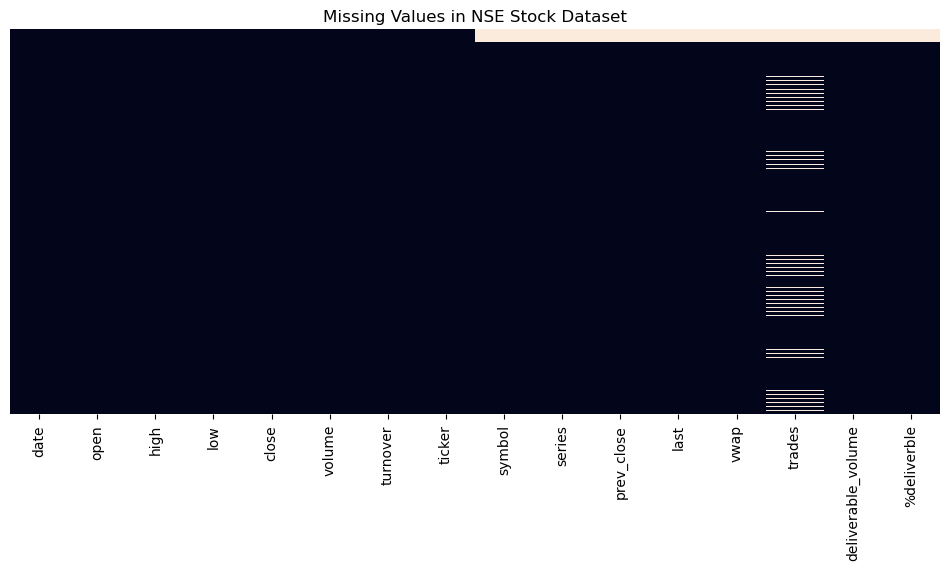

In [29]:
plt.figure(figsize=(12,5))
sns.heatmap(stock_data.isnull(),cbar=False,yticklabels=False)
plt.title("Missing Values in NSE Stock Dataset")
plt.show()

In [33]:
stock_data["date"]=pd.to_datetime(stock_data["date"],dayfirst=True,errors="coerce")
duplicates=stock_data.duplicated(subset=["ticker","date"],keep=False)
print("Duplicate records:",duplicates.sum())

Duplicate records: 0


In [32]:
stock_data=stock_data.drop_duplicates()

In [35]:
numeric_columns=["open","high","low","close","volume"]
for col in numeric_columns:
    if col in stock_data.columns:
        stock_data[col]=pd.to_numeric(stock_data[col].astype(str).str.replace(",",""),errors="coerce")

In [36]:
required=["open","high","low","close","volume"]
print("Missing required columns:",[c for c in required if c not in stock_data.columns])

Missing required columns: []


In [37]:
invalid_ohlc=(
    (stock_data["high"]<stock_data[["open","close","low"]].max(axis=1)) |
    (stock_data["low"]>stock_data[["open","close","high"]].min(axis=1))
)
negative_volume =stock_data["volume"]<0
print("Invalid OHLC records:",invalid_ohlc.sum())
print("Negative volume records:",negative_volume.sum())
print("Zero volume records:",(stock_data["volume"]==0).sum())

Invalid OHLC records: 0
Negative volume records: 0
Zero volume records: 0


In [38]:
invalid_rows = stock_data[
    stock_data["date"].isna() |
    stock_data[required].isna().any(axis=1) |
    invalid_ohlc |
    negative_volume
].copy()

print("Records requiring investigation:", len(invalid_rows))

Records requiring investigation: 16


In [41]:
cleaned_data = stock_data.dropna(
    subset=["date"] + required
).copy()
invalid_ohlc = (
    (cleaned_data["high"] <
     cleaned_data[["open", "close", "low"]].max(axis=1)) |
    (cleaned_data["low"] >
     cleaned_data[["open", "close", "high"]].min(axis=1))
)

negative_volume = cleaned_data["volume"] < 0

cleaned_data = cleaned_data[
    ~invalid_ohlc & ~negative_volume
].copy()

cleaned_data = cleaned_data.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

print("Cleaned dataset shape:", cleaned_data.shape)

Cleaned dataset shape: (252625, 16)


In [44]:
duplicates_dates=cleaned_data[cleaned_data.duplicated(subset=["ticker","date"],keep=False)]
print("Remaining duplicate ticker-date records:",len(duplicates_dates))
display(duplicates_dates.head(10))

Remaining duplicate ticker-date records: 0


,date,open,high,low,close,volume,turnover,ticker,symbol,series,prev_close,last,vwap,trades,deliverable_volume,%deliverble


In [45]:
cleaned_data=cleaned_data.sort_values(["ticker","date"])
cleaned_data["daily_return"]=(cleaned_data.groupby("ticker")["close"].pct_change()*100)
cleaned_data["price_range"]=(cleaned_data["high"]-cleaned_data["low"])
cleaned_data["price_change"]=(cleaned_data["close"]-cleaned_data["open"])
display(cleaned_data.head())

,date,open,high,low,close,volume,turnover,ticker,symbol,series,prev_close,last,vwap,trades,deliverable_volume,%deliverble,daily_return,price_range,price_change
0,2010-01-08,755.0,807.0,755.0,807.0,51.0,3.998995e+09,ABBOTINDIA,ABBOTINDIA,EQ,783.75,807.0,784.12,NaN,50.0,0.9804,NaN,52.0,52.0
1,2010-01-11,825.0,825.0,790.0,804.8,897.0,7.121265e+10,ABBOTINDIA,ABBOTINDIA,EQ,807.00,804.8,793.90,NaN,697.0,0.7770,-0.272615,35.0,-20.2
2,2010-01-12,800.0,805.0,790.0,790.0,426.0,3.405260e+10,ABBOTINDIA,ABBOTINDIA,EQ,804.80,790.0,799.36,NaN,401.0,0.9413,-1.838966,15.0,-10.0
3,2010-01-13,787.0,787.0,720.0,767.0,359.0,2.723129e+10,ABBOTINDIA,ABBOTINDIA,EQ,790.00,767.0,758.53,NaN,164.0,0.4568,-2.911392,67.0,-20.0
4,2010-01-14,769.0,798.0,769.0,785.1,317.0,2.509785e+10,ABBOTINDIA,ABBOTINDIA,EQ,767.00,785.1,791.73,NaN,122.0,0.3849,2.359844,29.0,16.1


In [46]:
output_path=PROCESSED_DIR/"cleaned_nse_top100.csv"
cleaned_data.to_csv(output_path,index=False)
print("Cleaned dataset saved successfully!")
print(output_path)

Cleaned dataset saved successfully!
C:\Users\haran\Documents\Infosys Springboard Internship\-AI-Powered-Multi-Agent-System-for-Market-Analysis-and-Research\multi-agent-stock-analyst\backend\Data\cleaned\cleaned_nse_top100.csv


In [47]:
invalid_rows.to_csv(PROCESSED_DIR/"invalid_records_for_review.csv",index=False)
print("Saved successfully")

Saved successfully


In [48]:
print("========== DATASET VALIDATION REPORT ==========")
print("Total records:", len(cleaned_data))
print("Total stocks:",cleaned_data["ticker"].nunique())
print("Date range:",cleaned_data["date"].min(),"to",cleaned_data["date"].max())
print("Missing values:")
print(cleaned_data.isnull().sum())
print("Duplicate ticker-date records:",cleaned_data.duplicated(subset=["ticker", "date"]).sum())
print("Volume zero records:",(cleaned_data["volume"] == 0).sum())
print("================================================")

========== DATASET VALIDATION REPORT ==========
Total records: 252625
Total stocks: 103
Date range: 2010-01-04 00:00:00 to 2020-10-01 00:00:00
Missing values:
date                      0
open                      0
high                      0
low                       0
close                     0
volume                    0
turnover                  0
ticker                    0
symbol                 7988
series                 7988
prev_close             7988
last                   7988
vwap                   7988
trades                38584
deliverable_volume     7988
%deliverble            7988
daily_return            103
price_range               0
price_change              0
dtype: int64
Duplicate ticker-date records: 0
Volume zero records: 0
